# PW8 - Logistic Regression

**Team:** Noé Berdoz, Michael Strefeler

## Our starting level

- **Noé Berdoz**: Bachelor in Business Information Technology (Informatique de gestion) at HE-Arc, completed in 2026. This programme focuses on software development and business processes and includes little mathematics, so _TODO: what was new for Noé in this PW_. He had almost no experience in machine learning before this course.
- **Michael Strefeler**: Bachelor in Computer and Communication Systems (ISC) at HEIG-VD, completed in 2025, with a specialisation in data science, so he had already seen some machine learning before this course. _TODO: what was new for Michael in this PW_

## Time spent

| Exercise | Time |
|---|---|
| Ex. 1 a - Linear decision boundary | yet a) to e) 1h40 |
| Ex. 1 b - Stochastic gradient ascent (optional) | 1h |
| Ex. 1 c - Non-linear decision boundary | _TODO_ |
| Ex. 1 d - Using scikit-learn | 1h |
| Ex. 2 - Classification on MNIST (optional) | 1h50 so far |
| Ex. 3 - Review questions | 20 min |
| **Total** | **_TODO_** |

## Bonus request

We would like to apply for the bonus for this PW.

**Why.** _TODO: in our own words, why we should get the bonus, measured against our starting levels_

**What we did as bonus**

- **Ex. 1** _TODO_
- **Ex. 2** _TODO_
- **Ex. 3** _TODO_

# Exercise 1 - Classification to predict student admission

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier

## Exercise steps

### a. Logistic regression classifier with linear decision boundary

#### a) Read the data from file

In a similar way as for the exercise of the previous week, read the training data from file `student-dataset-train.csv`. The first two columns are $x_{1}$ and $x_{2}$. The last column holds the class label $y$. Build the design matrix $X$ as follow:

$$X = \left(\begin{array}{ccc} 
        1 &   x_{1,1} & x_{1,2} \\
        1 &   \vdots  & \vdots  \\
        1 &   x_{N,1} & x_{N,2}
           \end{array}\right)$$

Check that the shape of $X$ is (100,3) and that the shape of $y$ is (100,).

            DATASET SUMMARY (TRAINING)            
- Shape of X: (100, 3)
- Shape of y: (100,)
- Class repartition: 60 admitted, 40 rejected
--------------------------------------------------
First 3 rows of X_train:
[[ 1.         34.62365962 78.02469282]
 [ 1.         30.28671077 43.89499752]
 [ 1.         35.84740877 72.90219803]]
First 3 labels of y_train:
[0 0 0]


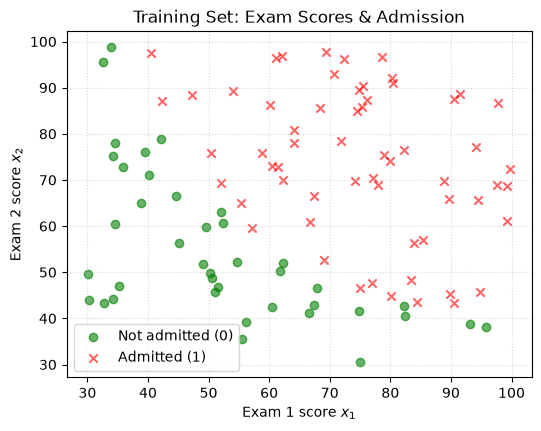

In [2]:
# Your code here
def read_data(file):
    dataset = pd.read_csv(file, names=['x1', 'x2', 'y'])
    return dataset[['x1', 'x2']].values, dataset['y'].values

x_train, y_train = read_data("student-dataset-train.csv")

N = x_train.shape[0]
X_train = np.ones((N, 3)) # column 0 stays at 1.0
X_train[:, 1] = x_train[:, 0] # exam 1
X_train[:, 2] = x_train[:, 1] # exam 2

print("=" * 50)
print(" DATASET SUMMARY (TRAINING)".center(50))
print("=" * 50)
print("- Shape of X:", X_train.shape)
print("- Shape of y:", y_train.shape)
print(f"- Class repartition: {np.sum(y_train == 1)} admitted, {np.sum(y_train == 0)} rejected")
print("-" * 50)
print("First 3 rows of X_train:")
print(X_train[:3])
print("First 3 labels of y_train:")
print(y_train[:3])
print("=" * 50)

# BONUS - a visualization with scatter plot
plt.figure(figsize=(6, 4.5))

plt.scatter(x_train[y_train == 0, 0], x_train[y_train == 0, 1],
            color='green', alpha=0.6,  marker='o', label='Not admitted (0)')

plt.scatter(x_train[y_train == 1, 0], x_train[y_train == 1, 1],
            color='red', alpha=0.6, marker='x', label='Admitted (1)')

plt.xlabel('Exam 1 score $x_1$')
plt.ylabel('Exam 2 score $x_2$')
plt.title('Training Set: Exam Scores & Admission')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

#### b) Implement a z-norm normalization of the training set

You need to store the normalization values $(\mu, \sigma)$ for later as they will be needed to normalize the test set.

         Z-SCORE NORMALIZATION (TRAINING)         
- Stored mu : [65.64, 66.22]
- Stored sigma: [19.36, 18.49]
- Mean after normalization: [-0.00, 0.00]
- Std after normalization: [1.00, 1.00]
--------------------------------------------------
First 3 rows of X_train_norm:
[[ 1.     -1.6022  0.6383]
 [ 1.     -1.8263 -1.2075]
 [ 1.     -1.539   0.3613]]


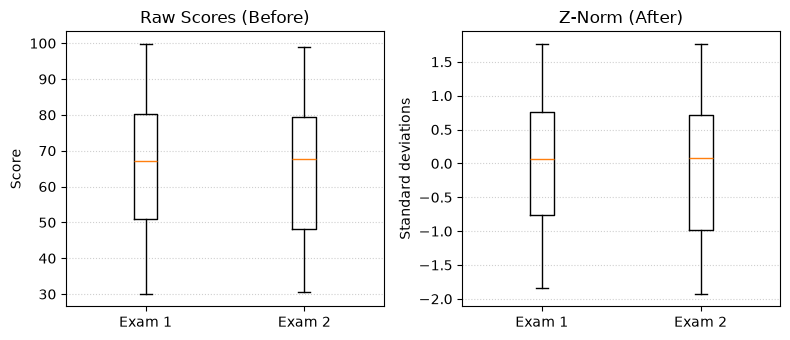

In [3]:
# Your code here
mu = np.mean(x_train, axis=0)
sigma = np.std(x_train, axis=0)

X_train_norm = np.ones((N, 3))
X_train_norm[:, 1] = (x_train[:, 0] - mu[0]) / sigma[0]
X_train_norm[:, 2] = (x_train[:, 1] -mu[1]) / sigma[1]

print("=" * 50)
print("Z-SCORE NORMALIZATION (TRAINING)".center(50))
print("=" * 50)
print(f"- Stored mu : [{mu[0]:.2f}, {mu[1]:.2f}]")
print(f"- Stored sigma: [{sigma[0]:.2f}, {sigma[1]:.2f}]")
print(f"- Mean after normalization: [{np.mean(X_train_norm[:, 1]):.2f}, {np.mean(X_train_norm[:, 2]):.2f}]")
print(f"- Std after normalization: [{np.std(X_train_norm[:, 1]):.2f}, {np.std(X_train_norm[:, 2]):.2f}]")
print("-" * 50)
print("First 3 rows of X_train_norm:")
print(np.round(X_train_norm[:3], 4))
print("=" * 50)

# BONUS - a visualization with boxplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5))

# 1. Before normalization plot
ax1.boxplot(x_train, tick_labels=['Exam 1', 'Exam 2'])
ax1.set_title('Raw Scores (Before)')
ax1.set_ylabel('Score')
ax1.grid(axis='y', linestyle=':', alpha=0.6)

# After normalization plot
ax2.boxplot(X_train_norm[:, 1:], tick_labels=['Exam 1', 'Exam 2'])
ax2.set_title('Z-Norm (After)')
ax2.set_ylabel('Standard deviations')
ax2.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

#### c) Implement a sigmoid function $g(z) = \frac{1}{1+e^{-z}}$

Use numpy to compute the exp so that your function can take numpy arrays as input. Check your implementation by plotting the sigmoid function.

                 SIGMOID FUNCTION                 
- Test inputs (z)      : [-3, 0, 3]
- Output probabilities : [0.0474, 0.5, 0.9526]
- Decision pivot (z=0) : g(0) = 0.5 (boundary threshold)
- Saturated bounds     : g(-8) = 0.0003, g(8) = 0.9997


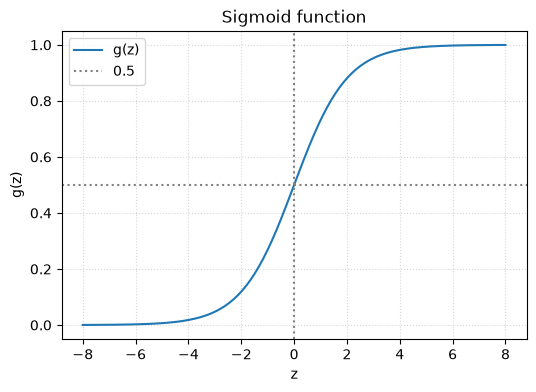

In [4]:
# Your code here
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("=" * 50)
print("SIGMOID FUNCTION".center(50))
print("=" * 50)
# Small test with the professor's input example during the course:
course_test_input  = np.array([-3, 0, 3])
print(f"- Test inputs (z)      : {course_test_input.tolist()}")
print(f"- Output probabilities : {np.round(sigmoid(course_test_input), 4).tolist()}")
print(f"- Decision pivot (z=0) : g(0) = {sigmoid(0):.1f} (boundary threshold)")
print(f"- Saturated bounds     : g(-8) = {sigmoid(-8):.4f}, g(8) = {sigmoid(8):.4f}")
print("=" * 50)

# Plot of the sigmoid curve
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 4))
plt.plot(z, sigmoid(z), label='g(z)')

# BONUS
# Show the decision threshold at P = 0.5
plt.axhline(0.5, color='gray', linestyle=':', label='0.5')
# Decision boundary pivot at z = 0 (where g(z) = 0.5)
plt.axvline(0, color='gray', linestyle=':')

plt.xlabel('z')
plt.ylabel('g(z)')
plt.title('Sigmoid function')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

#### d) Implement the hypothesis function $h_{\theta}(\mathbf{x})$

Hint: implement it so that the computation can take the full array $X$ with $h(\mathbf{x})$ broadcasted to all training samples.

In [5]:
# Your code here
def hypothesis(X, theta):
    return sigmoid(np.dot(X, theta))

h = hypothesis(X_train_norm, np.zeros(3))

print("=" * 50)
print("HYPOTHESIS FUNCTION".center(50))
print("=" * 50)
print("- Shape of h:", h.shape)
print(f"- First 3 predictions: {h[:3]}")
print(f"- Mean prediction: {np.mean(h[:3])}")
print("=" * 50)

               HYPOTHESIS FUNCTION                
- Shape of h: (100,)
- First 3 predictions: [0.5 0.5 0.5]
- Mean prediction: 0.5


#### e) Implement the objective function $J(\theta)$

$$J(\theta) = \frac{1}{N} \sum_{n=1}^{N} y_{n} \log h_{\theta}(\mathbf{x_{n}}) + (1-y_{n}) \log (1 - h_{\theta} (\mathbf{x_{n}}))$$

In [6]:
# Your code here
def objective(X, y, theta):
    epsilon = 1e-6
    h = hypothesis(X, theta)
    N = X.shape[0]
    tmp = y * np.log(h + epsilon) + (1 - y) * np.log(1 - h + epsilon)
    return np.sum(tmp) / N

print("=" * 50)
print("OBJECTIVE FUNCTION".center(50))
print("=" * 50)
print("- Computed J at theta = 0: ", objective(X_train_norm, y_train, np.zeros(3)))
print("- Expected log(0.5): ", np.log(0.5))
print("=" * 50)

                OBJECTIVE FUNCTION                
- Computed J at theta = 0:  -0.6931451805619452
- Expected log(0.5):  -0.6931471805599453


#### f) Implement the gradient ascent

In a similar way as in PW02 and PW03, implement the gradient ascent with the update rule:

$$\theta_{i} \leftarrow \theta_{i} + \alpha \frac{1}{N} \sum_{n=1}^{N} (y_{n} - h_{\theta}(\mathbf{x}_{n})) x_{n,i}$$

In [7]:
# Your code here

#### g) Test your implementation by running a gradient ascent

Hints: use a small $\alpha$. e.g. $0.001$,  store the evolution of the objective function $J(\theta)$ during the epochs to make a plot, use a large number of epochs, e.g. $2000000$.

In [8]:
# Your code here

#### h) Compute the correct classification rate on `student-dataset-test.csv`

Compute the correct classification rate on `student-dataset-test.csv` after convergence as you have an estimator of the posterior probabilities with:

$$P(y_{n}=1|\mathbf{x_{n}};\theta) = h_{\theta}(\mathbf{x_{n}})$$
$$P(y_{n}=0|\mathbf{x_{n}};\theta) = 1 - h_{\theta}(\mathbf{x_{n}})$$

This means that you can take the decisions $\hat{y}_{n} = 1$ if $h_{\theta}(\mathbf{x_{n}}) \geq 0.5$ and $\hat{y}_{n} = 0$ if $h_{\theta}(\mathbf{x_{n}}) < 0.5$.

In [9]:
# Your code here

#### i) Draw the decision boundary

Draw the decision boundary of your system on top of the scatter plot of the testing data.

In [10]:
# Your code here

#### j) Compare the performance

Compare the performance of the logistic regression system with the ones of previous's week.

In [11]:
# Your observation here

### b. Optional - Stochastic gradient ascent

Redo the experiments of 2.a with a stochastic gradient ascent.

In [12]:
# Your code here
def stochastic_gradient_ascent(X, y, alpha=0.001, max_epochs=2_000_000, epsilon=1e-6, seed=None, verbose=True):
    rng = np.random.default_rng(seed)
    N, D = X.shape

    thetas = np.zeros(D)

    # History used for plots, recorded once per epoch
    J_history = [objective(X, y, thetas)]   # J(theta) after each epoch
    theta_history = [thetas.copy()]         # thetas after each epoch

    for epoch in range(1, max_epochs + 1):
        # One epoch = N updates, each on 1 randomly drawn sample
        for _ in range(N):
            n = rng.integers(N)
            x_n = X[n]
            y_n = y[n]
            # Gradient of J for a single sample: (y_n - h(x_n)) * x_n
            thetas = thetas + alpha * (y_n - hypothesis(x_n, thetas)) * x_n

        # Convergence check on the full training set, once per epoch
        J = objective(X, y, thetas)
        J_history.append(J)
        theta_history.append(thetas.copy())

        if not np.isfinite(J):
            print("Diverged: try a smaller alpha")
            break

        # Relative change |J^(n) - J^(n-1)| / |J^(n)|
        rel_change = abs(J - J_history[-2]) / abs(J)
        if verbose and epoch % 100 == 0:
            print(f"epoch {epoch}: J = {J:.6f}, rel. change = {rel_change:.2e}, thetas = {np.round(thetas, 3)}")
        if rel_change < epsilon:
            print(f"Converged after {epoch} epochs ({epoch * N} updates)")
            break

    return thetas, np.array(J_history), np.array(theta_history)

epoch 100: J = -0.312482, rel. change = 3.03e-03, thetas = [0.479 1.282 1.142]
epoch 200: J = -0.262458, rel. change = 1.15e-03, thetas = [0.701 1.776 1.588]
epoch 300: J = -0.241983, rel. change = 5.60e-04, thetas = [0.804 2.096 1.897]
epoch 400: J = -0.231139, rel. change = 1.75e-04, thetas = [0.888 2.33  2.117]
epoch 500: J = -0.224556, rel. change = 4.24e-04, thetas = [0.983 2.498 2.275]
epoch 600: J = -0.219622, rel. change = 8.40e-05, thetas = [1.08  2.652 2.414]
epoch 700: J = -0.216581, rel. change = 1.25e-04, thetas = [1.158 2.747 2.532]
epoch 800: J = -0.214220, rel. change = 8.08e-05, thetas = [1.205 2.857 2.619]
Converged after 847 epochs (84700 updates)
- Final thetas: [1.2395 2.91   2.6502]
- Final J: -0.213309
- Training accuracy: 89.00%


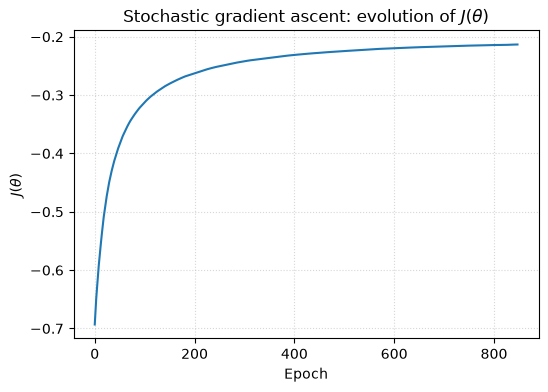

In [13]:
thetas_sga, J_hist_sga, theta_hist_sga = stochastic_gradient_ascent(X_train_norm, y_train, alpha=0.001, seed=0)

train_acc = np.mean((hypothesis(X_train_norm, thetas_sga) >= 0.5) == y_train)
print(f"- Final thetas: {np.round(thetas_sga, 4)}")
print(f"- Final J: {J_hist_sga[-1]:.6f}")
print(f"- Training accuracy: {train_acc:.2%}")

plt.figure(figsize=(6, 4))
plt.plot(J_hist_sga)
plt.xlabel('Epoch')
plt.ylabel(r'$J(\theta)$')
plt.title('Stochastic gradient ascent: evolution of $J(\\theta)$')
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

In [14]:
# Correct classification rate on the test set
x_test, y_test = read_data("student-dataset-test.csv")

# Normalize the test set with the mu and sigma of the TRAINING set
N_test = x_test.shape[0]
X_test_norm = np.ones((N_test, 3))
X_test_norm[:, 1] = (x_test[:, 0] - mu[0]) / sigma[0]
X_test_norm[:, 2] = (x_test[:, 1] - mu[1]) / sigma[1]

# Decision: y_hat = 1 if h(x) >= 0.5, else 0
y_pred_sga = (hypothesis(X_test_norm, thetas_sga) >= 0.5).astype(int)
test_acc_sga = np.mean(y_pred_sga == y_test)

print("=" * 50)
print("STOCHASTIC GRADIENT ASCENT - TEST SET".center(50))
print("=" * 50)
print(f"- Correct classification rate: {test_acc_sga:.2%} ({np.sum(y_pred_sga == y_test)}/{N_test})")
print(f"- Misclassified samples: {np.sum(y_pred_sga != y_test)}")
print("=" * 50)

      STOCHASTIC GRADIENT ASCENT - TEST SET       
- Correct classification rate: 89.00% (89/100)
- Misclassified samples: 11


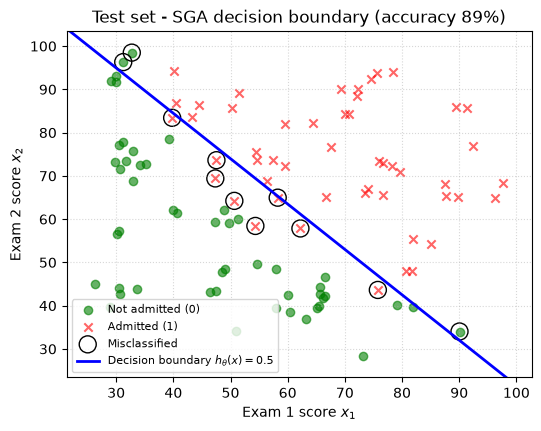

In [15]:
# Decision boundary: h(x) = 0.5  <=>  theta_0 + theta_1 * z1 + theta_2 * z2 = 0
# with z = (x - mu) / sigma, so solving for x2 in original units:
# x2 = mu2 - sigma2 / theta_2 * (theta_0 + theta_1 * (x1 - mu1) / sigma1)
def decision_boundary_x2(x1, thetas, mu, sigma):
    z1 = (x1 - mu[0]) / sigma[0]
    z2 = -(thetas[0] + thetas[1] * z1) / thetas[2]
    return mu[1] + sigma[1] * z2

x1_line = np.linspace(x_test[:, 0].min() - 5, x_test[:, 0].max() + 5, 100)
x2_line = decision_boundary_x2(x1_line, thetas_sga, mu, sigma)

plt.figure(figsize=(6, 4.5))
plt.scatter(x_test[y_test == 0, 0], x_test[y_test == 0, 1],
            color='green', alpha=0.6, marker='o', label='Not admitted (0)')
plt.scatter(x_test[y_test == 1, 0], x_test[y_test == 1, 1],
            color='red', alpha=0.6, marker='x', label='Admitted (1)')

# Circle the misclassified test samples
wrong = y_pred_sga != y_test
plt.scatter(x_test[wrong, 0], x_test[wrong, 1], s=150, facecolors='none',
            edgecolors='black', label='Misclassified')

plt.plot(x1_line, x2_line, color='blue', lw=2, label=r'Decision boundary $h_\theta(x)=0.5$')

plt.xlim(x_test[:, 0].min() - 5, x_test[:, 0].max() + 5)
plt.ylim(x_test[:, 1].min() - 5, x_test[:, 1].max() + 5)
plt.xlabel('Exam 1 score $x_1$')
plt.ylabel('Exam 2 score $x_2$')
plt.title(f'Test set - SGA decision boundary (accuracy {test_acc_sga:.0%})')
plt.legend(loc='lower left', fontsize=8)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

### c. Logistic regression classifier with non-linear decision boundary

Redo the experiments of 2.a by increasing the complexity of the model in order to have a non-linear decision boundary:

$$h_{\theta}(\mathbf{x}) = g(\theta_{0} + \theta_{1} x_{1} + \theta_{2} x_{2} + \theta_{3} x_{1}^{2} + \theta_{4} x_{2}^{2} + \theta_{5} x_{1}x_{2} + \ldots)$$

In [16]:
# Your code here

### d. Using SciKit Learn

Redo one of the exercise a. or c. using SciKit Learn.

1. Read the documentation of the function `SGDClassifier()` available in the toolkit SciKit Learn. This function implements stochastic gradient descent training for different linear systems such as Logistic Regression. For a logistic regression, the `loss` parameter should be set to `"log"`.
1. Use the `fit()` and `predict()` methods of this classifier on the student data.
1. Compute the performances and compare it to your own implementations.

In [ ]:
# Your code here
import warnings
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.exceptions import ConvergenceWarning

def sklearn_logistic_regression(degree, seed=0):
    """PolynomialFeatures builds the extra columns (x1^2, x2^2, x1*x2, ...) as in exercise c.
    degree=1 keeps only x1, x2, which is exercise a.
    StandardScaler does the z-norm (mu and sigma are learned on the training set only).
    SGDClassifier with loss="log_loss" is a logistic regression trained with SGD.
    penalty=None: no L2 regularization, like our own gradient ascent.
    learning_rate="constant": with no penalty, the default "optimal" schedule takes huge
    steps and stops after a few epochs, which gives very different results per seed."""
    return make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        SGDClassifier(loss="log_loss", penalty=None, learning_rate="constant", eta0=0.01,
                      max_iter=5000, tol=1e-6, n_iter_no_change=20, random_state=seed),
    )

In [18]:

models = {}
print("=" * 60)
print("SCIKIT-LEARN SGDClassifier (logistic regression)".center(60))
print("=" * 60)
print(f"{'Model':<22}{'Train acc.':>12}{'Test acc.':>12}{'Epochs':>10}")
print("-" * 60)
for degree, name in [(1, "a. linear (deg 1)"), (2, "c. quadratic (deg 2)")]:
    model = sklearn_logistic_regression(degree)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(x_train, y_train)
    converged = not any(issubclass(wi.category, ConvergenceWarning) for wi in w)
    models[degree] = model
    print(f"{name:<22}{model.score(x_train, y_train):>12.2%}{model.score(x_test, y_test):>12.2%}"
          f"{model[-1].n_iter_:>10}{'' if converged else ' (max_iter)'}")
print("=" * 60)

      SCIKIT-LEARN SGDClassifier (logistic regression)      
Model                   Train acc.   Test acc.    Epochs
------------------------------------------------------------
a. linear (deg 1)           89.00%      89.00%       390
c. quadratic (deg 2)       100.00%      95.00%      5000 (max_iter)


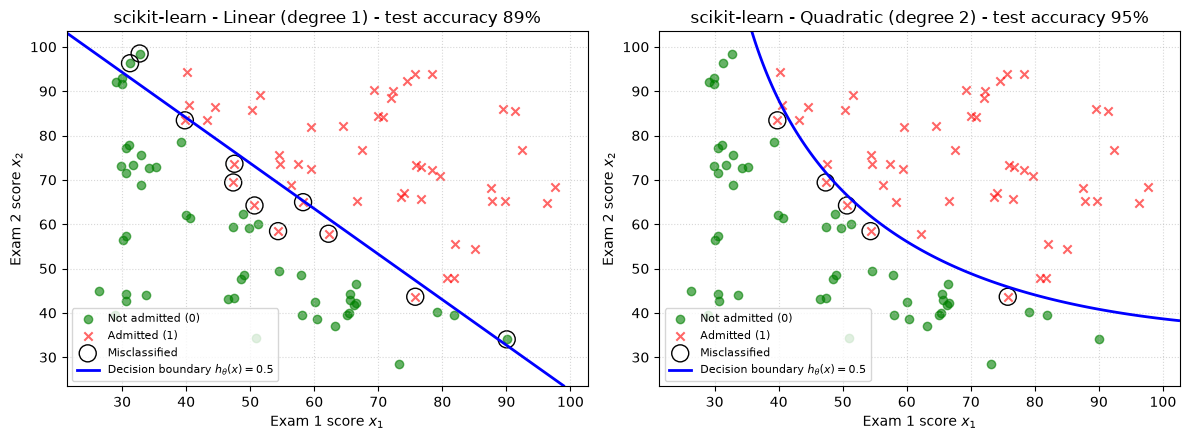

In [19]:
# Decision boundaries on the test set: h(x) = 0.5, drawn as a contour of predict_proba on a grid
# (works for any degree, unlike the closed-form line of exercise a)
x1_grid, x2_grid = np.meshgrid(
    np.linspace(x_test[:, 0].min() - 5, x_test[:, 0].max() + 5, 300),
    np.linspace(x_test[:, 1].min() - 5, x_test[:, 1].max() + 5, 300),
)
grid = np.column_stack([x1_grid.ravel(), x2_grid.ravel()])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (degree, title) in zip(axes, [(1, "Linear (degree 1)"), (2, "Quadratic (degree 2)")]):
    model = models[degree]
    proba = model.predict_proba(grid)[:, 1].reshape(x1_grid.shape)
    y_pred = model.predict(x_test)
    wrong = y_pred != y_test

    ax.scatter(x_test[y_test == 0, 0], x_test[y_test == 0, 1],
               color='green', alpha=0.6, marker='o', label='Not admitted (0)')
    ax.scatter(x_test[y_test == 1, 0], x_test[y_test == 1, 1],
               color='red', alpha=0.6, marker='x', label='Admitted (1)')
    ax.scatter(x_test[wrong, 0], x_test[wrong, 1], s=150, facecolors='none',
               edgecolors='black', label='Misclassified')
    ax.contour(x1_grid, x2_grid, proba, levels=[0.5], colors='blue', linewidths=2)
    ax.plot([], [], color='blue', lw=2, label=r'Decision boundary $h_\theta(x)=0.5$')

    ax.set_xlabel('Exam 1 score $x_1$')
    ax.set_ylabel('Exam 2 score $x_2$')
    ax.set_title(f'scikit-learn - {title} - test accuracy {np.mean(~wrong):.0%}')
    ax.legend(loc='lower left', fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

TODO: compare with c. when it's done

- Degree 1 (exercise a): same result as our own stochastic gradient ascent from b., 89% on train and test.
- Degree 2 (exercise c): 100% on train, 95% on test. The slides give 94% for c. SGD runs until `max_iter`: with quadratic features the training set is perfectly separable, and with `penalty=None` the weights keep growing because nothing stops them.